Pass
Pass    265
Fail    130
Name: count, dtype: int64


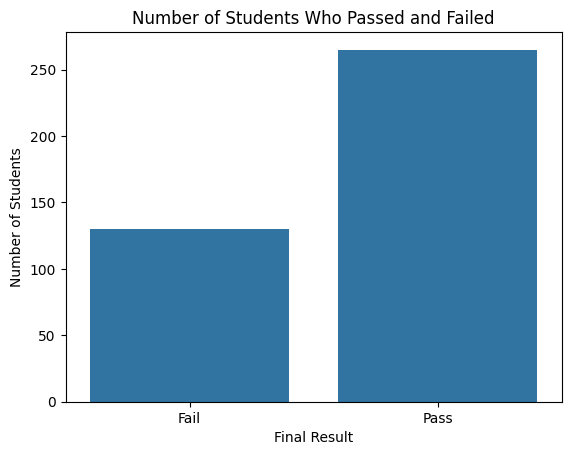

Accuracy: 0.8734177215189873
Precision: 0.9574468085106383
Recall: 0.8490566037735849
F1 Score: 0.9

Classification Report:
              precision    recall  f1-score   support

        Fail       0.75      0.92      0.83        26
        Pass       0.96      0.85      0.90        53

    accuracy                           0.87        79
   macro avg       0.85      0.89      0.86        79
weighted avg       0.89      0.87      0.88        79



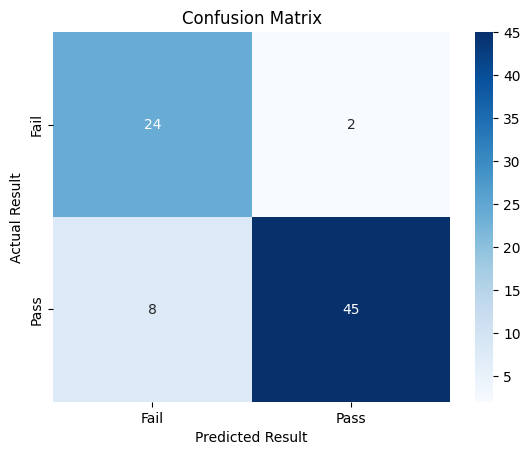


Five Incorrect Predictions:
     age  studytime  failures  absences  G1  G2 Actual Predicted
43    15          1         0         0   8   8   Pass      Fail
283   18          2         0         4   8   9   Pass      Fail
281   17          1         1        19  11   9   Pass      Fail
2     15          2         3        10   7   8   Pass      Fail
199   16          2         0         0   9   9   Pass      Fail

Total Incorrect Predictions: 10


In [13]:

# libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import zipfile

# 2. Load dataset
with zipfile.ZipFile("archive.zip") as archive:
    with archive.open("student_data.csv") as file:
        df = pd.read_csv(file)


# 3. Clean the dataset
df.columns = df.columns.str.strip()

df = df.drop_duplicates()
df["G3"] = pd.to_numeric(df["G3"], errors="coerce")

df = df.dropna(subset=["G3"])
df = df[(df["G3"] >= 0) & (df["G3"] <= 20)]


# Create the Pass/Fail target
# A final grade of 10 or higher is a Pass
# A final grade below 10 is a Fail

df["Pass"] = (df["G3"] >= 10).astype(int)
print(df["Pass"].value_counts().rename(index={0: "Fail", 1: "Pass"}))


# 5. Visualize the Pass/Fail distribution
sns.countplot(data=df, x="Pass")
plt.xticks([0, 1], ["Fail", "Pass"])
plt.title("Number of Students Who Passed and Failed")
plt.xlabel("Final Result")
plt.ylabel("Number of Students")
plt.show()


# 6. Select features and target
# G3 is removed because it was used to create the Pass/Fail target

X = df.drop(columns=["G3", "Pass"])
y = df["Pass"]


# 7. Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object", "category"]).columns


# 8. Prepare the data
# Fill missing numerical values with the median
# Fill missing categorical values with the most common value

numeric_transformer = sklearn.pipeline.Pipeline(steps=[
    ("imputer", sklearn.impute.SimpleImputer(strategy="median"))
])

categorical_transformer = sklearn.pipeline.Pipeline(steps=[
    ("imputer", sklearn.impute.SimpleImputer(strategy="most_frequent")),
    ("encoder", sklearn.preprocessing.OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = sklearn.compose.ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


# 9. Split the data into training and testing sets
X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# 10. Create and train the Random Forest model
model = sklearn.pipeline.Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", sklearn.ensemble.RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)


# 11. Make predictions
y_pred = model.predict(X_test)


# 12. Evaluate model performance
print("Accuracy:", sklearn.metrics.accuracy_score(y_test, y_pred))
print("Precision:", sklearn.metrics.precision_score(y_test, y_pred, zero_division=0))
print("Recall:", sklearn.metrics.recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", sklearn.metrics.f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(sklearn.metrics.classification_report(
    y_test,
    y_pred,
    target_names=["Fail", "Pass"],
    zero_division=0
))


# 13. Create a confusion matrix
conf_matrix = sklearn.metrics.confusion_matrix(y_test, y_pred)

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.show()


#  Find five incorrect predictions
incorrect = X_test.copy()

incorrect["Actual"] = y_test
incorrect["Predicted"] = y_pred

# Keep only predictions that were incorrect
incorrect = incorrect[incorrect["Actual"] != incorrect["Predicted"]].copy()

# Change 0 and 1 into PASS and Fail  labels
incorrect["Actual"] = incorrect["Actual"].map({0: "Fail", 1: "Pass"})
incorrect["Predicted"] = incorrect["Predicted"].map({0: "Fail", 1: "Pass"})

# Display five incorrect predictions
print("\nFive Incorrect Predictions:")

columns_to_show = [
    col for col in ["age", "studytime", "failures", "absences", "G1", "G2"]
    if col in incorrect.columns
]

columns_to_show += ["Actual", "Predicted"]

print(incorrect[columns_to_show].head(5))

# Show how many incorrect predictions there were in total
print("\nTotal Incorrect Predictions:", len(incorrect))
